<div style="background-color: steelblue; padding: 10px; border-radius: 5px;">
    <p style="margin: 10;"></p>
    <h1 style="text-align: center; margin: 0; font-weight: bold; color: white;">SWOT OMIP : Seasonality ratio</h1>
    <p style="margin: 10;"></p>
</div>


## 📦**Imports** 

In [1]:
%%time

##################################
#Imports

from datetime import datetime
import s3fs
import xarray as xr
import pyinterp
from widetrax import DataPreprocessing as dp
from widetrax import Spectra as sp
import numpy as np
import json
from watermark import watermark
import time
import platform
from shapely.geometry import shape, box

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
#from widetrax import Spectra as sp
#import plot_psd1Xglobal1 as pp2X
import cum_sp_onl_season_v3 as cs
import importlib
importlib.reload(cs)
import position_function as pf
importlib.reload(pf)

CPU times: user 2.45 s, sys: 895 ms, total: 3.35 s
Wall time: 7.12 s


<module 'position_function' from '/Users/contrema/Documents/Postdoc/SWOTv2/position_function.py'>

## **Map plot functions**

In [2]:


def plot_fig(ax,imodel,lon_edges,lat_edges,ZW,ZS,valmin,valmax,model,posx,posy,abc,box_pos,box_neg):
    ax[posx,posy].add_feature(cfeature.COASTLINE)
    ax[posx,posy].add_feature(cfeature.LAND, facecolor="lightgray")
    mesh = ax[posx,posy].pcolormesh(
        lon_edges,
        lat_edges,
        np.squeeze(ZW[imodel,:,:]/ZS[imodel,:,:]),
        vmin=valmin,
        vmax=valmax,
        cmap='seismic',
        transform=ccrs.PlateCarree()
    )
    ax[posx,posy].text(30, 60,f"Boxes >1: {box_pos[imodel]}",transform=ccrs.PlateCarree(),fontsize=8,fontweight='bold',
                      bbox=dict(facecolor='white', alpha=0.6, edgecolor='none'))
    ax[posx,posy].text(30, 40,f"Boxes <1: {box_neg[imodel]}",transform=ccrs.PlateCarree(),fontsize=8,fontweight='bold',
                      bbox=dict(facecolor='white', alpha=0.6, edgecolor='none'))
    ax[posx,posy].set_title(abc + model[imodel])
    ax[posx,posy] = ax[posx,posy].gridlines(draw_labels=True,linewidth=0.2)
    ax[posx,posy].bottom_labels = True
    ax[posx,posy].top_labels = False
    ax[posx,posy].right_labels = False
    ax[posx,posy].left_labels = True
    ax[posx,posy].xlines = False
    ax[posx,posy].ylines = False
    return ax, mesh

## **Load boxes position**

In [3]:
boxesjson="mostly_ocean_boxes_filtered.geojson"
north_boxes, south_boxes=pf.position_boxes_northsouth(boxesjson) # selection of northern and southern hemisphere boxes
selected=pf.position_boxes(boxesjson) # Index boxes for global ocean, and the region

North boxes: 93
South boxes: 189


## **Load Spectrum**

In [4]:
# -----------------------------
# Analysis for 50-150 km
# -----------------------------
#Define Wavelength range
min_wavelength=50
max_wavelength=150
# models
models=["GLO12V4","GLO36V1","NOC12","NOC025","LLC4320","SWOT"]

# psdsW winter spectrum list / psdsS summer spectrum list 
psdsW, psdsS,freqJAS=cs.season_cum(models,selected,min_wavelength,max_wavelength,north_boxes,south_boxes, "https://minio.dive.edito.eu/",
                                   'JFM','JAS',modeload="online",folder="project-meom-ige/OMIP/Global/")

#  reorganice values of every boxes into a map: ZW (spectrum winter) and ZS (spectrum summer)
ZW,ZS=cs.remap(psdsW,psdsS,models)


/Users/contrema/Documents/Postdoc/SWOTv2/cum_sp_onl_season_v3.py:102: RuntimeWarning: divide by zero encountered in divide
  wavelength=1/np.array(freqJFM)


## **Plotting**
  

[199. 174. 166. 147. 156. 196.]
[ 83. 108. 116. 135. 126.  86.]


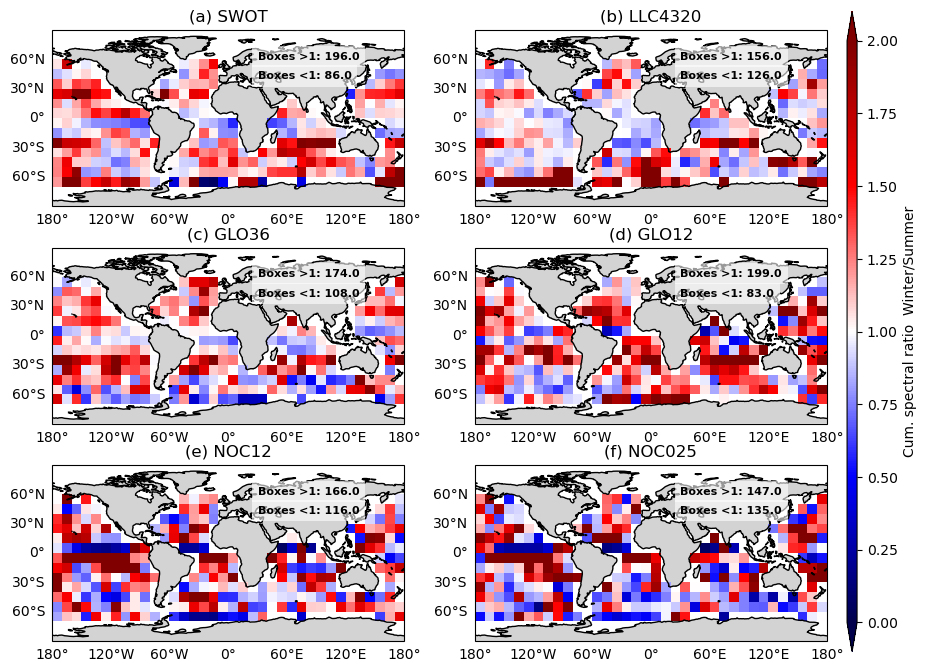

In [8]:
model= ["GLO12","GLO36","NOC12","NOC025","LLC4320","SWOT"]
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
box_pos=np.zeros((6))
box_neg=np.zeros((6))

for imodel in range(6):
    box_neg[imodel]=len(np.where(ZW[imodel,:,:]/ZS[imodel,:,:]<1)[0])
    box_pos[imodel]=len(np.where(ZW[imodel,:,:]/ZS[imodel,:,:]>1)[0])


print(box_pos)
print(box_neg)

min_wavelength=50
max_wavelength=150
lon_edges = np.arange(-180, 181, 10)
lat_edges = np.arange(-90, 91, 10)

valmin=0
valmax=2
fig, ax = plt.subplots(3, 2,figsize=(10, 8),subplot_kw={'projection': ccrs.PlateCarree()})
fig.subplots_adjust(wspace=0.2, hspace=0.2)
#ax = plt.axes(projection=ccrs.PlateCarree())
imodel=5
ax, mesh=plot_fig(ax,imodel,lon_edges,lat_edges,ZW,ZS,valmin,valmax,model,0,0,'(a) ',box_pos,box_neg)
imodel=4
ax, mesh=plot_fig(ax,imodel,lon_edges,lat_edges,ZW,ZS,valmin,valmax,model,0,1,'(b) ',box_pos,box_neg)
imodel=1
ax, mesh=plot_fig(ax,imodel,lon_edges,lat_edges,ZW,ZS,valmin,valmax,model,1,0,'(c) ',box_pos,box_neg)
imodel=0
ax, mesh=plot_fig(ax,imodel,lon_edges,lat_edges,ZW,ZS,valmin,valmax,model,1,1,'(d) ',box_pos,box_neg)
imodel=2
ax, mesh=plot_fig(ax,imodel,lon_edges,lat_edges,ZW,ZS,valmin,valmax,model,2,0,'(e) ',box_pos,box_neg)
imodel=3
ax, mesh=plot_fig(ax,imodel,lon_edges,lat_edges,ZW,ZS,valmin,valmax,model,2,1,'(f) ',box_pos,box_neg)



#plt.colorbar(mesh, ax=ax[0,0], orientation="vertical")
cbar_ax = fig.add_axes([0.92, 0.1, 0.01, .8])
cbar = fig.colorbar(mesh,cax=cbar_ax, orientation='vertical', fraction=0.02,  extend='both')
cbar.set_label("Cum. spectral ratio  Winter/Summer")
plt.savefig("FigV2/cumspectrumratio_model_{}-{}.png".format(min_wavelength,max_wavelength),dpi=300,transparent=False)
plt.show()

